# Regression: a reversible reaction in a batch reactor

**CHME 5137, homework after Lectures 12 and 13 (October 20 and 23, 2026).** Section 5 of
the Lecture 13 notebook started this. Here it is in full.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's A ⇌ B fitting
exercise of earlier years, and checked by Prof. West.*

---

You run a reversible, first-order reaction in a batch reactor:
$$\mathrm{A} \rightleftharpoons \mathrm{B}, \qquad
\frac{dC_A}{dt} = k_r C_B - k_f C_A, \qquad C_B = C_{A,0} - C_A$$
Every run starts with $C_{A,0} = 10$ mol/L and no B. You measured $C_A$ every 10 s for
100 s, at three temperatures.

**Kinetics.** The forward rate constant follows the Arrhenius expression,
$k_f = A \exp(-E_a/RT)$.

**Thermodynamics.** At equilibrium the forward and reverse rates are equal, so the
equilibrium constant is $K = k_f/k_r$. (Assume an ideal solution, so this
concentration-based $K$ is the thermodynamic one.) From thermodynamics,
$$\Delta G^\circ = -RT\ln K \qquad\text{and}\qquad \Delta G^\circ = \Delta H - T\,\Delta S$$
A and B have very similar heat capacities, so take $\Delta H$ and $\Delta S$ to be
independent of temperature. Then $k_r = k_f/K$, and the whole model has **four
parameters**: $\log_{10} A$, $E_a$, $\Delta H$ and $\Delta S$.

Before the experiments, from the literature and a quantum chemistry calculation, your
estimates were $\log_{10}A \approx 6$ (A in s⁻¹), $E_a \approx 45$ kJ/mol,
$\Delta H \approx -10$ kJ/mol and $\Delta S \approx -50$ J/mol/K. Let's see what the data say.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then commit
  with a message that says what you did, and push. At least one commit per task.
  **Commit the `.ipynb` and its paired `.py` together.**
- **Answer the questions in words**, in the markdown cells marked *Answer*.
- **Say what your ± means.** One standard error, or a 95% interval? Either is fine. Say which (Lecture 13).
- **Let bugs shout.** If `solve_ivp` fails, `raise` an error with its `message`.
  Don't let a half-finished solution reach `curve_fit` without anyone noticing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate
import scipy.optimize
import scipy.stats

plt.rcParams['figure.figsize'] = [5, 3]
R = 8.314  # J/mol/K

The data, the same as in class:

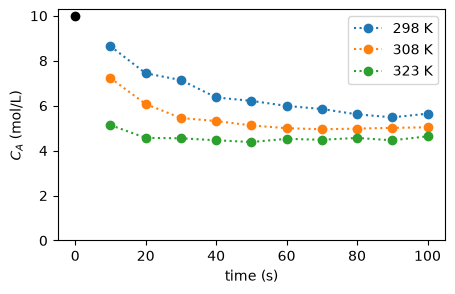

In [2]:
cA0 = 10.0   # mol/L
times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])   # s
cA_data = {   # mol/L, keyed by temperature in K
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data))

for T, cA in cA_data.items():
    plt.plot(times, cA, 'o:', label=f'{T:.0f} K')
plt.plot(0, cA0, 'ko')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, None)
plt.legend()
plt.show()

## 1. One temperature

**(a) The model.** Write `cA_model(times, kf, kr)`, which solves the ODE with
`scipy.integrate.solve_ivp` and returns $C_A$ at `times` (use `t_eval`). In Lecture 13 we fitted
functions that were a formula. `curve_fit` doesn't care: any function that takes the
independent variable first and then the parameters, and returns predictions, will do. Even
one that runs a whole simulation.

Then **test it** (Lecture 11). This ODE has an exact solution,
$$C_A(t) = C_{A,\mathrm{eq}} + (C_{A,0} - C_{A,\mathrm{eq}})\,e^{-(k_f+k_r)t},
\qquad C_{A,\mathrm{eq}} = C_{A,0}\frac{k_r}{k_f+k_r}$$
Check that your function agrees with it, for some reasonable $k_f$ and $k_r$, with an
`assert`. (We use `solve_ivp` anyway because your project's model won't have an exact
solution.)

In [3]:
def cA_model(times, kf, kr):
    """C_A (mol/L) at each of `times` (s), for rate constants kf and kr (1/s)."""

    def dC_dt(t, y):
        Ca = y[0]
        Cb = cA0 - Ca
        dCa_dt = kr * Cb - kf * Ca
        return [dCa_dt]

    sol = scipy.integrate.solve_ivp(dC_dt, t_span = (0, times[-1]), y0 = [cA0], t_eval = times)
    if not sol.success:
        raise RuntimeError(sol.message)

    return sol.y[0]

kf_guess = 0.05
kr_guess = 0.02

ca_eq = cA0 * (kr_guess / (kf_guess + kr_guess))
ca_exact = ca_eq + (cA0 - ca_eq) * np.exp(-(kf_guess + kr_guess) * times)

ca_sim = cA_model(times, kf_guess, kr_guess)
np.testing.assert_allclose(ca_sim, ca_exact, rtol=1e-3, atol=1e-4)

# your test here

**(b) Fit it at 298.15 K**, with `scipy.optimize.curve_fit`. **Try it without `p0` first.**
It may fail with an error from deep inside SciPy, or it may appear to succeed. Either way,
find out what happened: print and plot what came back, or what `cA_model` returns
at `curve_fit`'s default starting point. Then give it a starting guess you can justify
from the data. Roughly how long does $C_A$ take to get halfway to where it ends up?

In [4]:
# Without p0

try:
    popt_1, pcov_1 = scipy.optimize.curve_fit(cA_model, times, cA_data[298.15])
    print("popt without p0:", popt_1)
except Exception as e:
    print("Error without p0:", e)

popt without p0: [0.61131177 1.10550764]


In [5]:
p0_guess = [0.015, 0.02]
popt, pcov = scipy.optimize.curve_fit(cA_model, times, cA_data[298.15], p0=p0_guess)
perr = np.sqrt(np.diag(pcov))

print(f"kf = {popt[0]:.5f} ± {perr[0]:.5f} 1/s")
print(f"kr = {popt[1]:.5f} ± {perr[1]:.5f} 1/s")

kf = 0.01679 ± 0.00079 1/s
kr = 0.02004 ± 0.00154 1/s


**(c) Look at it.** Plot the data and the fitted curve, and below it the residuals
(data minus model). Report $k_f$ and $k_r$ with their uncertainties.

What happened without `p0`, and why? What starting guess did you use, and how did you
choose it?

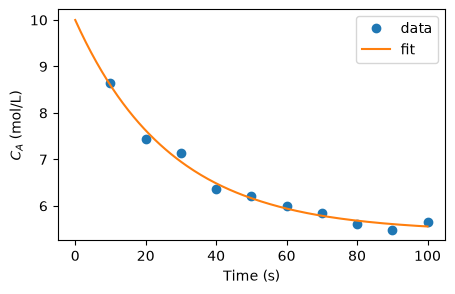

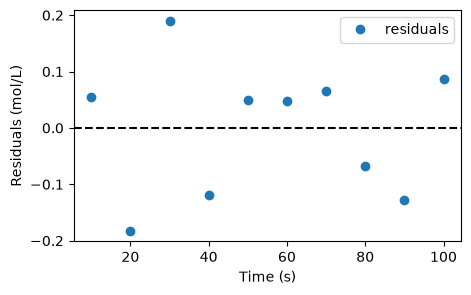

In [6]:
t_plot = np.linspace(0, 100, 200)
cA_fit = cA_model(t_plot, *popt)
cA_fit_points = cA_model(times, *popt)
residuals = cA_data[298.15] - cA_fit_points

plt.plot(times, cA_data[298.15], 'o', label='data')
plt.plot(t_plot, cA_fit, '-', label='fit')
plt.xlabel('Time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.legend()
plt.show()

plt.plot(times, residuals, 'o', label='residuals')
plt.axhline(0, color='k', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Residuals (mol/L)')
plt.legend()
plt.show()

*Answer: At 298.15 K, the fitted rate constants are $k_f = 0.0168 \pm 0.0008\text{ s}^{-1}$ and $k_r = 0.0200 \pm 0.0015\text{ s}^{-1}$. Each $\pm$ denotes one standard error ($1\sigma$) taken from the square root of the diagonal elements of pcov. 

Without p0, curve_fit defaulted to [1.0, 1.0]. Rate constants of $1\text{ s}^{-1}$ give a relaxation time $\tau \approx 0.5\text{ s}$, meaning the simulated reaction reached equilibrium well before our first measurement at 10 s. Over the entire 10–100 s window, the predicted curve was completely flat. Because the gradient with respect to reaction rate vanished, the optimizer could not determine which way to step and became trapped in a flat minimum, only shifting the plateau to the average concentration.

To find a justified starting guess, we used the data's plateau and timescale. Concentration levels off near $5.6\text{ mol/L}$, so $C_{A,\text{eq}}/C_{A,0} = k_r / (k_f + k_r) \approx 5.6/10 = 0.56$. It reaches the halfway point ($7.8\text{ mol/L}$) by $t_{1/2} \approx 20\text{ s}$. This gives $k_f + k_r \approx \ln(2)/20 \approx 0.035\text{ s}^{-1}$, yielding $k_r \approx 0.020\text{ s}^{-1}$ and $k_f \approx 0.015\text{ s}^{-1}$ for p0.*

## 2. Three temperatures, in two steps

**(a)** Fit $k_f$ and $k_r$ separately at each temperature, and make a small table of
$k_f$, $k_r$ (each with its ±) and $K = k_f/k_r$.

**Before fitting anything else:** from your $K$ values alone, is the reaction endothermic
or exothermic? How can you tell?

In [7]:
results = []
T_vals = np.array(list(cA_data.keys()))
kf_vals = []
kr_vals = []
K_vals = []

print(f"{'T (K)':<10}{'kf (1/s)':<22}{'kr (1/s)':<22}{'K = kf/kr':<12}")
print("-" * 66)

for T in T_vals:
    popt, pcov = scipy.optimize.curve_fit(cA_model, times, cA_data[T], p0=[0.02, 0.02])
    perr_T = np.sqrt(np.diag(pcov))

    kf, kr = popt
    K = kf / kr
    
    kf_vals.append(kf)
    kr_vals.append(kr)
    K_vals.append(K)

    print(f"{T:<10.2f}{kf:.5f} ± {perr_T[0]:.5f}    {kr:.5f} ± {perr_T[1]:.5f}    {K:.4f}")

T (K)     kf (1/s)              kr (1/s)              K = kf/kr   
------------------------------------------------------------------
298.15    0.01679 ± 0.00079    0.02004 ± 0.00154    0.8377
308.15    0.03924 ± 0.00085    0.03921 ± 0.00105    1.0006
323.15    0.11942 ± 0.00651    0.09791 ± 0.00570    1.2196


The reaction is endothermic. As the temperature increases from 298.15 K to 323.15 K, the equilibrium constant $K = k_f / k_r$ increases from 0.8377 to 1.2196. When raising the temperature causes $K$ to increase, the forward reaction is favored to absorb the added heat. Therefore, heat is absorbed, so $\Delta H > 0$.

**(b) Arrhenius.** As in Lecture 13: `scipy.stats.linregress` on $\ln k_f$ against
$1/T$ gives $E_a$ from the slope and $\ln A$ from the intercept. Convert $\ln A$ to
$\log_{10} A$.

**(c) van 't Hoff.** Put the two expressions for $\Delta G^\circ$ together and divide by $-RT$:
$$\ln K = -\frac{\Delta H}{R}\,\frac{1}{T} + \frac{\Delta S}{R}$$
So $\ln K$ against $1/T$ is a straight line too, with slope $-\Delta H/R$ and intercept
$\Delta S/R$. Fit it, and get $\Delta H$ and $\Delta S$, with their ±. Does the sign of
$\Delta H$ agree with what you said in (a)?

In [8]:
R = 8.314  # J/mol/K

inverse_T = 1 / T_vals
ln_kf = np.log(kf_vals)

result_arrhenius = scipy.stats.linregress(inverse_T, ln_kf)

slope = result_arrhenius.slope
slope_err = result_arrhenius.stderr
intercept = result_arrhenius.intercept
intercept_err = result_arrhenius.intercept_stderr

Ea = -slope * R / 1000
Ea_err = slope_err * R / 1000

log10_A = intercept / np.log(10)
log10_A_err = intercept_err / np.log(10)

print(f"Ea       = {Ea:.2f} ± {Ea_err:.2f} kJ/mol")
print(f"log10(A) = {log10_A:.2f} ± {log10_A_err:.2f}")
print(f"R^2      = {result_arrhenius.rvalue**2:.4f}")

Ea       = 62.77 ± 0.95 kJ/mol
log10(A) = 9.23 ± 0.16
R^2      = 0.9998


In [9]:
ln_K = np.log(K_vals)

result_vant_hoff = scipy.stats.linregress(inverse_T, ln_K)

dH = -result_vant_hoff.slope * R / 1000
dH_err = result_vant_hoff.stderr * R / 1000

dS = result_vant_hoff.intercept * R
dS_err = result_vant_hoff.intercept_stderr * R

print(f"dH  = {dH:.2f} ± {dH_err:.2f} kJ/mol")
print(f"dS  = {dS:.2f} ± {dS_err:.2f} J/(mol K)")
print(f"R^2 = {result_vant_hoff.rvalue**2:.4f}")

dH  = 11.97 ± 0.74 kJ/mol
dS  = 38.72 ± 2.38 J/(mol K)
R^2 = 0.9962


**(d)** `linregress` gave you a ± on each of these. What does that ± know about,
and what has it left out? Think about how many points each straight line had, and about
the ± you got in (a).

*Answer: The error bars reported by linregress come entirely from the vertical scatter of the three fitted points around the best-fit line. SciPy estimates the noise variance purely from the residuals of this line and projects it onto the slope and intercept standard errors. What they leave out is the uncertainty of each individual point. The rate constants $k_f$, $k_r$, and $K$ determined from the reactor data in step 2(a) each had their own standard errors and correlations from pcov. Ordinary linear regression ignores these known individual error bars completely, treating all three points as equally and infinitely certain measurements.*

## 3. All the data at once

Step 2 fitted 3 × 2 rate constants, then fitted lines through three points each. Better:
fit the four parameters you actually want **directly to all 30 measurements**, so that
every measurement counts and the uncertainties carry all the way through.

`curve_fit` wants one `xdata` and one `ydata`. With several experiments, stack them:
`ydata` is all 30 concentrations in one array, and `xdata` carries **both** the
temperature and the time of each one. `curve_fit` never looks inside `xdata`; it just passes it
to your function. So it can be a tuple of two arrays:

In [10]:
T_all = np.repeat(temperatures, len(times))     # 298.15 ten times, then 308.15 ten times, ...
t_all = np.tile(times, len(temperatures))        # 10, 20, ..., 100, three times over
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)
print(T_all[:12], t_all[:12], cA_all[:12], sep='\n')

[298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15
 308.15 308.15]
[ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.  10.  20.]
[8.649 7.441 7.141 6.366 6.215 5.99  5.852 5.615 5.481 5.644 7.23  6.073]


**(a)** Write `cA_model_all(x, log10A, Ea, dH, dS)`. Unpack `x` into temperatures and
times. For each temperature, work out $k_f$, $K$ and $k_r$, then call your `cA_model` for
that temperature's times, and put the results in the right places of the output array.
Solve one ODE per temperature, not one per data point. A boolean mask such as
`T_col == T` picks out the rows.

Notice the **units**: $E_a$ and $\Delta H$ in kJ/mol, $\Delta S$ in J/mol/K, and $A$ as
$\log_{10}A$. That keeps all four parameters between about 1 and 100. An optimizer
has an easier time when its parameters are all a similar size than when one is
$10^{9}$ and another is $10^{-2}$. So convert carefully inside the function.

Then fit it, **starting from your answers to task 2**, and report the four parameters with
their ±.

In [11]:
T_list = []
t_list = []
cA_list = []

for T, cA_vals in cA_data.items():
    for t_val, cA_val in zip(times, cA_vals):
        T_list.append(T)
        t_list.append(t_val)
        cA_list.append(cA_val)

T_all = np.array(T_list)
t_all = np.array(t_list)
cA_all = np.array(cA_list)

def cA_model_all(x, log10A, Ea, dH, dS):
    """C_A (mol/L) for every (T, t) pair in x. Ea and dH in kJ/mol, dS in J/mol/K."""
    T_col, t_col = x
    cA_pred = np.zeros_like(T_col, dtype=float)

    A = 10**log10A
    Ea_J = Ea * 1000
    dH_J = dH * 1000

    for T_val in np.unique(T_col):
        kf = A * np.exp(-Ea_J / (R * T_val))
        dG = dH_J - T_val * dS
        K = np.exp(-dG / (R * T_val))
        kr = kf / K

        mask = (T_col == T_val)
        cA_pred[mask] = cA_model(t_col[mask], kf, kr)

    return cA_pred

p0_sim = [log10_A, Ea, dH, dS]

popt_all, pcov_all = scipy.optimize.curve_fit(cA_model_all, (T_all, t_all), cA_all, p0=p0_sim)
perr_all = np.sqrt(np.diag(pcov_all))

para_names = ['log10(A)', 'Ea (kJ/mol)', 'dH (kJ/mol)', 'dS (J/(mol K)']
for name, val, err in zip(para_names, popt_all, perr_all):
    print(f"{name:<15} = {val:.2f} ± {err:.2f}")
    


log10(A)        = 9.48 ± 0.37
Ea (kJ/mol)     = 64.28 ± 2.14
dH (kJ/mol)     = 11.53 ± 0.79
dS (J/(mol K)   = 37.33 ± 2.51


**(b)** Now start from your estimates from before the experiments instead (6, 45, −10, −50).
Does it find the same answer? How far did the data move you from what you expected?

In [12]:
p0_test = [6.0, 45.0, -10.0, -50.0]

popt_test, pcov_test = scipy.optimize.curve_fit(cA_model_all, (T_all, t_all), cA_all, p0=p0_test)
for name, val in zip(para_names, popt_test):
    print(f"{name:<15} = {val:.2f}")

log10(A)        = 37.19
Ea (kJ/mol)     = 222.14
dH (kJ/mol)     = 14.32
dS (J/(mol K)   = 45.54


No, the optimizer does not find the same answer. Starting from [6, 45, -10, -50] caused curve_fit to run for over 40 seconds and get trapped in an unphysical local minimum with $\log_{10}(A) \approx 37.19$ and $E_a \approx 222.14\text{ kJ/mol}$. 

The real data moved our estimates significantly away from the prior expectations. Most critically, the thermodynamics flipped from exothermic ($\Delta H = -10\text{ kJ/mol}$) to endothermic ($\Delta H \approx +11.53\text{ kJ/mol}$), and the reaction entropy increased from $-50$ to $+37.33\text{ J/(mol}\cdot\text{K)}$. The activation energy also shifted higher from $45\text{ kJ/mol}$ to $64.28\text{ kJ/mol}$, with $\log_{10}(A)$ moving from $6.0$ to $9.48$

**(c)** Compare with task 2. Are the centres the same? Are the error bars? Which set of
error bars would you believe, and why?

**(d) The correlation matrix.** The off-diagonal elements of `pcov` say how the errors in
the parameters go together (Lecture 13). Turn the covariance into correlations:
`pcov / np.outer(perr, perr)`. Which pairs are strongly correlated? Why those pairs?
(Think about Lecture 13's ridge, and about the range of temperatures you measured over.)
If someone quotes only your four ± values, what are they missing?

In [13]:
correlation_matrix = pcov_all / np.outer(perr_all, perr_all)

print(f"{'':>15}" + "".join([f"{name:>15}" for name in para_names]))
print("-" * 75)
for i, name in enumerate(para_names):
    row_str = f"{name:>15}" + "".join([f"{correlation_matrix[i, j]:>15.4f}" for j in range(4)])
    print(row_str)

                      log10(A)    Ea (kJ/mol)    dH (kJ/mol)  dS (J/(mol K)
---------------------------------------------------------------------------
       log10(A)         1.0000         0.9997        -0.3701        -0.3730
    Ea (kJ/mol)         0.9997         1.0000        -0.3807        -0.3832
    dH (kJ/mol)        -0.3701        -0.3807         1.0000         0.9996
  dS (J/(mol K)        -0.3730        -0.3832         0.9996         1.0000


*Answer:
(c) The parameter values between the two methods agree very closely. The activation energy $E_a$ is $62.77\text{ kJ/mol}$ in the two-step fit versus $64.28\text{ kJ/mol}$ in the simultaneous fit, and the enthalpy $\Delta H$ is $11.97\text{ kJ/mol}$ versus $11.53\text{ kJ/mol}$.

The simultaneous fit reports larger, more realistic error bars—for example, the uncertainty on $E_a$ widened from $\pm 0.95$ to $\pm 2.14\text{ kJ/mol}$. In Task 2, linregress fit three isolated summary points, ignoring the individual measurement errors on $k_f$ and $K$ and artificially shrinking the reported standard errors. The simultaneous fit regresses the actual 30 concentration data points directly through the integrated ODE, properly propagating all experimental noise across the shared parameters.

(d) The correlation matrix shows that $\log_{10}(A)$ and $E_a$ have a correlation of $0.9997$, and $\Delta H$ and $\Delta S$ have a correlation of $0.9996$.

This happens because over a narrow temperature range ($298.15\text{ to }323.15\text{ K}$), the parameters compensate for each other. In the Arrhenius equation $\ln k = \ln A - E_a / (RT)$, increasing $E_a$ slows the reaction down, but increasing $\ln A$ speeds it right back up. The same balance happens in thermodynamics with $\Delta G = \Delta H - T\Delta S$.

Because they can cancel each other out, the optimizer sees a long, narrow diagonal valley instead of a single round point. Reporting isolated $\pm$ error bars leaves this out: you cannot change one parameter without also sliding its partner along that ridge.*

## 4. Look at the residuals

**Always look at the residuals** (Lecture 13). Plot the residuals of the task 3 fit against
time, one colour per temperature, with a line at zero.

- Do you see a pattern, or does it look like noise?
- Is the scatter about the same width at all three temperatures? Least squares assumed it is.
- Nobody told you the measurement uncertainty, so `curve_fit` (with
  `absolute_sigma=False`, the default) estimated it from the scatter of the residuals.
  Work out that estimate yourself:
  $s = \sqrt{\sum_i r_i^2 / (N - p)}$, with $N$ data points and $p$ parameters. What does
  it say about how precisely $C_A$ was measured?
- Suppose the experimentalist now tells you their instrument is good to ±0.01 mol/L.
  What would that tell you about your model, or about the experiment?

Degrees of freedom: 26
Estimated noise   : 0.0886 mol/L


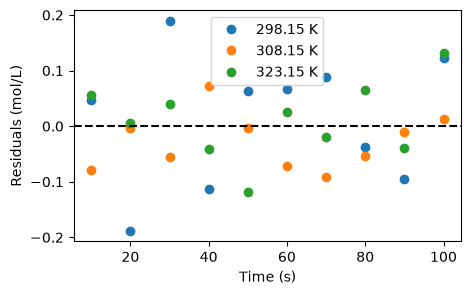

In [14]:
cA_pred_all = cA_model_all((T_all, t_all), *popt_all)
residuals_all = cA_all - cA_pred_all

N = len(cA_all)
p = len(popt_all)
degrees_of_freedom = N - p
s_n = np.sqrt(np.sum(residuals_all**2) / degrees_of_freedom)

print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"Estimated noise   : {s_n:.4f} mol/L")

for T_val in np.unique(T_all):
    mask = (T_all == T_val)
    plt.plot(t_all[mask], residuals_all[mask], 'o', label=f'{T_val} K')

plt.axhline(0, color='k', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Residuals (mol/L)')
plt.legend()
plt.show()

*Answer: The estimated experimental noise across all 30 points is $s = 0.0886\text{ mol/L}$ with 26 degrees of freedom. The residual plot shows random scatter centered around zero with no apparent systematic drift or curvature over time, confirming that the first-order reversible kinetic model captures the reaction behavior well across all three temperatures.

However, this result does not support the experimentalist's claimed measurement precision of $\pm 0.01\text{ mol/L}$. Our estimated noise $s \approx 0.09\text{ mol/L}$ is nearly nine times larger than the claimed error. The measurements have noticeably more random scatter than expected from an instrument with $\pm 0.01\text{ mol/L}$ precision.*

## 5. Your project

One paragraph. Which parameters in your project's model will come from fitting data, and
where will the data come from: your own simulations, the literature, a research group? What
can you say about the errors in those data? Are they the same absolute size, the same
relative size, or known point by point? And are any of your parameters likely to be
correlated, the way $E_a$ and $A$ are here?

*Answer:*

## Stretch problems (optional)

**(a) Untangle the ridge.** Write $k_f$ in terms of its value at a reference temperature in
the middle of your data, say $T_\mathrm{ref} = 310$ K:
$$k_f(T) = k_\mathrm{ref}\exp\left[-\frac{E_a}{R}\left(\frac{1}{T} - \frac{1}{T_\mathrm{ref}}\right)\right]$$
It's the same model, written differently. Fit $\log_{10}k_\mathrm{ref}$, $E_a$, $\Delta H$
and $\Delta S$, and look at the correlation matrix again. What changed, and why? Can you do
the same for $\Delta H$ and $\Delta S$?

**(b) Draw the posterior.** At 298.15 K only, put $k_f$ and $k_r$ on a 2-D grid and draw
their posterior, as in Lecture 13, part 5, with a flat prior and Gaussian errors of width
$s$ from task 4. Do its 95% credible intervals (summed over the other parameter) agree with
`curve_fit`'s 95% confidence intervals? Why should they, or why not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors, and that the plots
are there. Commit and push. Then check on GitHub that your fork shows your latest commit.